# Customer Churn Prediction: From Data to Ensemble Models
**Course:** Data Science | **Assignment 5** | Telco Customer Churn dataset

**Goal:** Predict whether a customer will leave (`Churn`) using Logistic Regression, Decision Trees, Random Forest and XGBoost, then compare them.

**Plan**
1. Data preprocessing and feature engineering
2. Baseline model: Logistic Regression
3. Decision Trees and overfitting analysis
4. Ensemble learning (Random Forest and XGBoost)
5. Model evaluation and comparison

## Step 0: Import libraries

In [6]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

sns.set_style("whitegrid")
RANDOM_STATE = 42   # makes results reproducible
print("Libraries imported successfully")

Libraries imported successfully


# Part 1: Data Preprocessing and Feature Engineering
### 1.1 Load the dataset

In [7]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 1.2 Fix the `TotalCharges` column
`TotalCharges` should be a number, but pandas reads it as text (`object`) because some rows contain empty strings (`" "`).
We use `pd.to_numeric(..., errors="coerce")`, which turns anything that is not a number into `NaN` (missing). Then we drop those rows.

In [9]:
print("Data type before:", df["TotalCharges"].dtype)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Data type after :", df["TotalCharges"].dtype)
print("Missing values in TotalCharges:", df["TotalCharges"].isna().sum())

Data type before: object
Data type after : float64
Missing values in TotalCharges: 11


In [10]:
# These are customers with tenure = 0 (brand new), so they have no charges yet
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [11]:
rows_before = len(df)
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)
print(f"Rows before: {rows_before} | Rows after: {len(df)} | Dropped: {rows_before - len(df)}")
print("Total missing values left:", df.isna().sum().sum())

Rows before: 7043 | Rows after: 7032 | Dropped: 11
Total missing values left: 0


### 1.3 Quick look at the target (`Churn`)
This shows how imbalanced the data is: far more customers stay than leave. That matters later when we look at Recall.

Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn
No     73.4
Yes    26.6
Name: proportion, dtype: float64 %


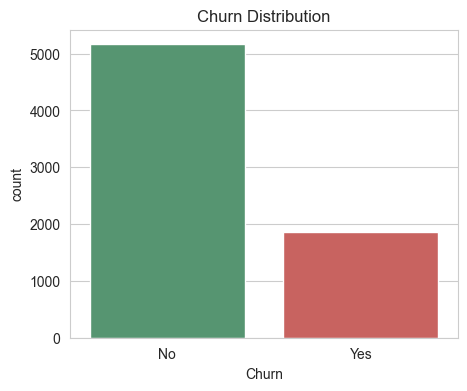

In [12]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3) * 100, "%")

plt.figure(figsize=(5, 4))
sns.countplot(x="Churn", data=df, palette=["#4C9F70", "#D9534F"])
plt.title("Churn Distribution")
plt.show()

### 1.4 Convert the target to binary and drop the ID column
- `Churn`: Yes → 1, No → 0
- `customerID` is just a unique label with no predictive meaning, so we drop it (otherwise One-Hot Encoding would create thousands of useless columns).

In [13]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df = df.drop(columns=["customerID"])
print(df["Churn"].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


### 1.5 One-Hot Encoding (drop the first category)
Machine learning models need numbers, not text. One-Hot Encoding turns each category into its own 0/1 column.
`drop_first=True` removes one category per feature to avoid **multicollinearity** (the "dummy variable trap").

In [14]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("Categorical columns to encode:", categorical_cols)

df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)
print("\nShape after encoding:", df_encoded.shape)
df_encoded.head()

Categorical columns to encode: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Shape after encoding: (7032, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


### 1.6 Train / Test split (80 / 20, stratified)
`stratify=y` keeps the same churn percentage in both the training and testing sets.

In [15]:
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Churn rate  full: {y.mean():.3f} | train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

X_train: (5625, 30) | X_test: (1407, 30)
Churn rate  full: 0.266 | train: 0.266 | test: 0.266


### 1.7 Standardize numerical features
`StandardScaler` rescales values to mean 0 and standard deviation 1.
**To avoid data leakage:** we `fit` the scaler on the **training data only**, then `transform` both training and test data using those training statistics.
We only scale the truly numeric columns (`tenure`, `MonthlyCharges`, `TotalCharges`). The 0/1 dummy columns stay as they are.

In [16]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit + transform on TRAIN
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])         # only transform on TEST

print("Train means after scaling (should be ~0):")
print(X_train_scaled[num_cols].mean().round(3))
print("\nTrain std after scaling (should be ~1):")
print(X_train_scaled[num_cols].std().round(3))

Train means after scaling (should be ~0):
tenure           -0.0
MonthlyCharges    0.0
TotalCharges      0.0
dtype: float64

Train std after scaling (should be ~1):
tenure            1.0
MonthlyCharges    1.0
TotalCharges      1.0
dtype: float64


# Part 2: Baseline Modeling with Logistic Regression
Logistic Regression is a simple, fast model that gives each feature a **coefficient**:
- **Positive** coefficient → feature increases churn risk
- **Negative** coefficient → feature decreases churn risk

In [17]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

print("Logistic Regression training accuracy:", round(log_reg.score(X_train_scaled, y_train), 4))
print("Logistic Regression testing accuracy :", round(log_reg.score(X_test_scaled, y_test), 4))

Logistic Regression training accuracy: 0.8048
Logistic Regression testing accuracy : 0.8045


### 2.1 Extract the coefficients

In [18]:
coef_df = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Coefficient": log_reg.coef_[0]
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)

print("Top 10 features that INCREASE churn risk:")
display(coef_df.head(10))
print("Top 10 features that DECREASE churn risk:")
display(coef_df.tail(10).iloc[::-1])

Top 10 features that INCREASE churn risk:


,Feature,Coefficient
0,InternetService_Fiber optic,1.121685
1,TotalCharges,0.641811
2,PaymentMethod_Electronic check,0.386286
3,StreamingTV_Yes,0.374880
4,MultipleLines_Yes,0.362680
5,StreamingMovies_Yes,0.347601
6,PaperlessBilling_Yes,0.290723
7,SeniorCitizen,0.195363
8,PaymentMethod_Mailed check,0.076969
9,DeviceProtection_Yes,0.073764


Top 10 features that DECREASE churn risk:


,Feature,Coefficient
29,tenure,-1.355817
28,Contract_Two year,-1.351225
27,Contract_One year,-0.743489
26,PhoneService_Yes,-0.522947
25,MonthlyCharges,-0.445174
24,OnlineSecurity_Yes,-0.370820
23,TechSupport_Yes,-0.329742
22,Dependents_Yes,-0.231842
21,MultipleLines_No phone service,-0.183234
20,OnlineSecurity_No internet service,-0.168056


### 2.2 Horizontal bar chart of the top positive and negative features

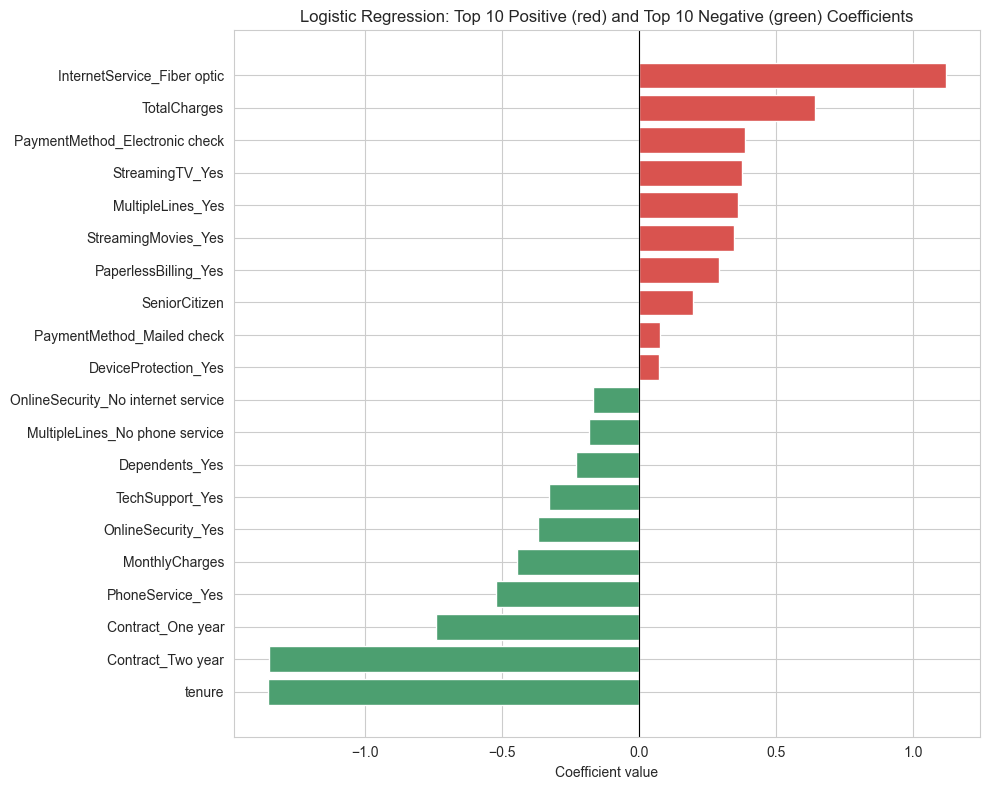

In [19]:
top_pos = coef_df.head(10)
top_neg = coef_df.tail(10)
plot_df = pd.concat([top_pos, top_neg]).sort_values("Coefficient")

colors = ["#D9534F" if c > 0 else "#4C9F70" for c in plot_df["Coefficient"]]

plt.figure(figsize=(10, 8))
plt.barh(plot_df["Feature"], plot_df["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient value")
plt.title("Logistic Regression: Top 10 Positive (red) and Top 10 Negative (green) Coefficients")
plt.tight_layout()
plt.show()

**How to read this chart**
- **Red bars (positive):** these push the prediction toward *churn*.
- **Green bars (negative):** these push the prediction toward *staying*. For example, a longer `tenure` or a longer contract means a lower chance of leaving.
- The longer the bar, the stronger the influence. Numeric features were scaled, so their coefficients are comparable.
- **Strongest churn risks:** `InternetService_Fiber optic` (largest positive), then `TotalCharges`, `PaymentMethod_Electronic check`, and streaming services.
- **Strongest protection against churn:** `tenure` and `Contract_Two year` (both about -1.35), then `Contract_One year`, `PhoneService`, `OnlineSecurity` and `TechSupport`.
- **Note:** `MonthlyCharges` and `TotalCharges` are strongly correlated with `tenure` and with the service columns, so their individual coefficients can look surprising (here `MonthlyCharges` is negative). Linear models split credit between correlated features, so we interpret them with care.

# Part 3: Decision Trees and Overfitting Analysis
A Decision Tree learns a series of if/else questions to classify customers. It can capture non-linear patterns, but if we let it grow without limits it will **memorize** the training data (overfitting).

### 3.1 Unconstrained Decision Tree (entropy criterion)

In [20]:
dt_full = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
dt_full.fit(X_train_scaled, y_train)

dt_full_train_acc = dt_full.score(X_train_scaled, y_train)
dt_full_test_acc = dt_full.score(X_test_scaled, y_test)

print("Unconstrained Decision Tree")
print(f"  Depth of tree     : {dt_full.get_depth()}")
print(f"  Number of leaves  : {dt_full.get_n_leaves()}")
print(f"  Training accuracy : {dt_full_train_acc:.4f}")
print(f"  Testing accuracy  : {dt_full_test_acc:.4f}")

Unconstrained Decision Tree
  Depth of tree     : 29
  Number of leaves  : 1045
  Training accuracy : 0.9988
  Testing accuracy  : 0.7278


### 3.2 Pruned Decision Tree (max_depth = 5, min_samples_leaf = 50)

In [21]:
dt_pruned = DecisionTreeClassifier(criterion="entropy", max_depth=5, min_samples_leaf=50,
                                   random_state=RANDOM_STATE)
dt_pruned.fit(X_train_scaled, y_train)

dt_pruned_train_acc = dt_pruned.score(X_train_scaled, y_train)
dt_pruned_test_acc = dt_pruned.score(X_test_scaled, y_test)

print("Pruned Decision Tree")
print(f"  Depth of tree     : {dt_pruned.get_depth()}")
print(f"  Number of leaves  : {dt_pruned.get_n_leaves()}")
print(f"  Training accuracy : {dt_pruned_train_acc:.4f}")
print(f"  Testing accuracy  : {dt_pruned_test_acc:.4f}")

Pruned Decision Tree
  Depth of tree     : 5
  Number of leaves  : 24
  Training accuracy : 0.7927
  Testing accuracy  : 0.7754


### 3.3 Compare the two trees

,Model,Train Accuracy,Test Accuracy,Gap (Train - Test)
0,Unconstrained Tree,0.9988,0.7278,0.2710
1,Pruned Tree,0.7927,0.7754,0.0173


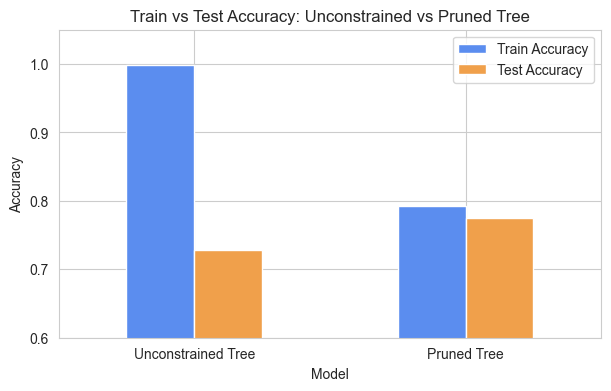

In [22]:
tree_compare = pd.DataFrame({
    "Model": ["Unconstrained Tree", "Pruned Tree"],
    "Train Accuracy": [dt_full_train_acc, dt_pruned_train_acc],
    "Test Accuracy": [dt_full_test_acc, dt_pruned_test_acc],
})
tree_compare["Gap (Train - Test)"] = tree_compare["Train Accuracy"] - tree_compare["Test Accuracy"]
display(tree_compare.round(4))

tree_compare.set_index("Model")[["Train Accuracy", "Test Accuracy"]].plot(
    kind="bar", figsize=(7, 4), color=["#5B8DEF", "#F0A04B"])
plt.ylim(0.6, 1.05)
plt.title("Train vs Test Accuracy: Unconstrained vs Pruned Tree")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.show()

**Discussion: overfitting**
- The **unconstrained tree** grew to depth 29 with 1,045 leaves. It scored about **99.9% on training** data but only about **72.8% on test** data. A gap of roughly 27 points is a clear sign of **overfitting**: the tree memorized noise in the training data instead of learning general patterns.
- The **pruned tree** is deliberately limited (max depth 5, at least 50 samples per leaf, 24 leaves). It scored about **79.3% on training** and **77.5% on test**, a gap of under 2 points, and its test accuracy is higher than the unconstrained tree's.
- **Conclusion:** the pruned tree **generalizes better** and avoids overfitting. A model that performs well on unseen data is more useful than one that only memorizes the training set.

### 3.4 Visualize the pruned tree

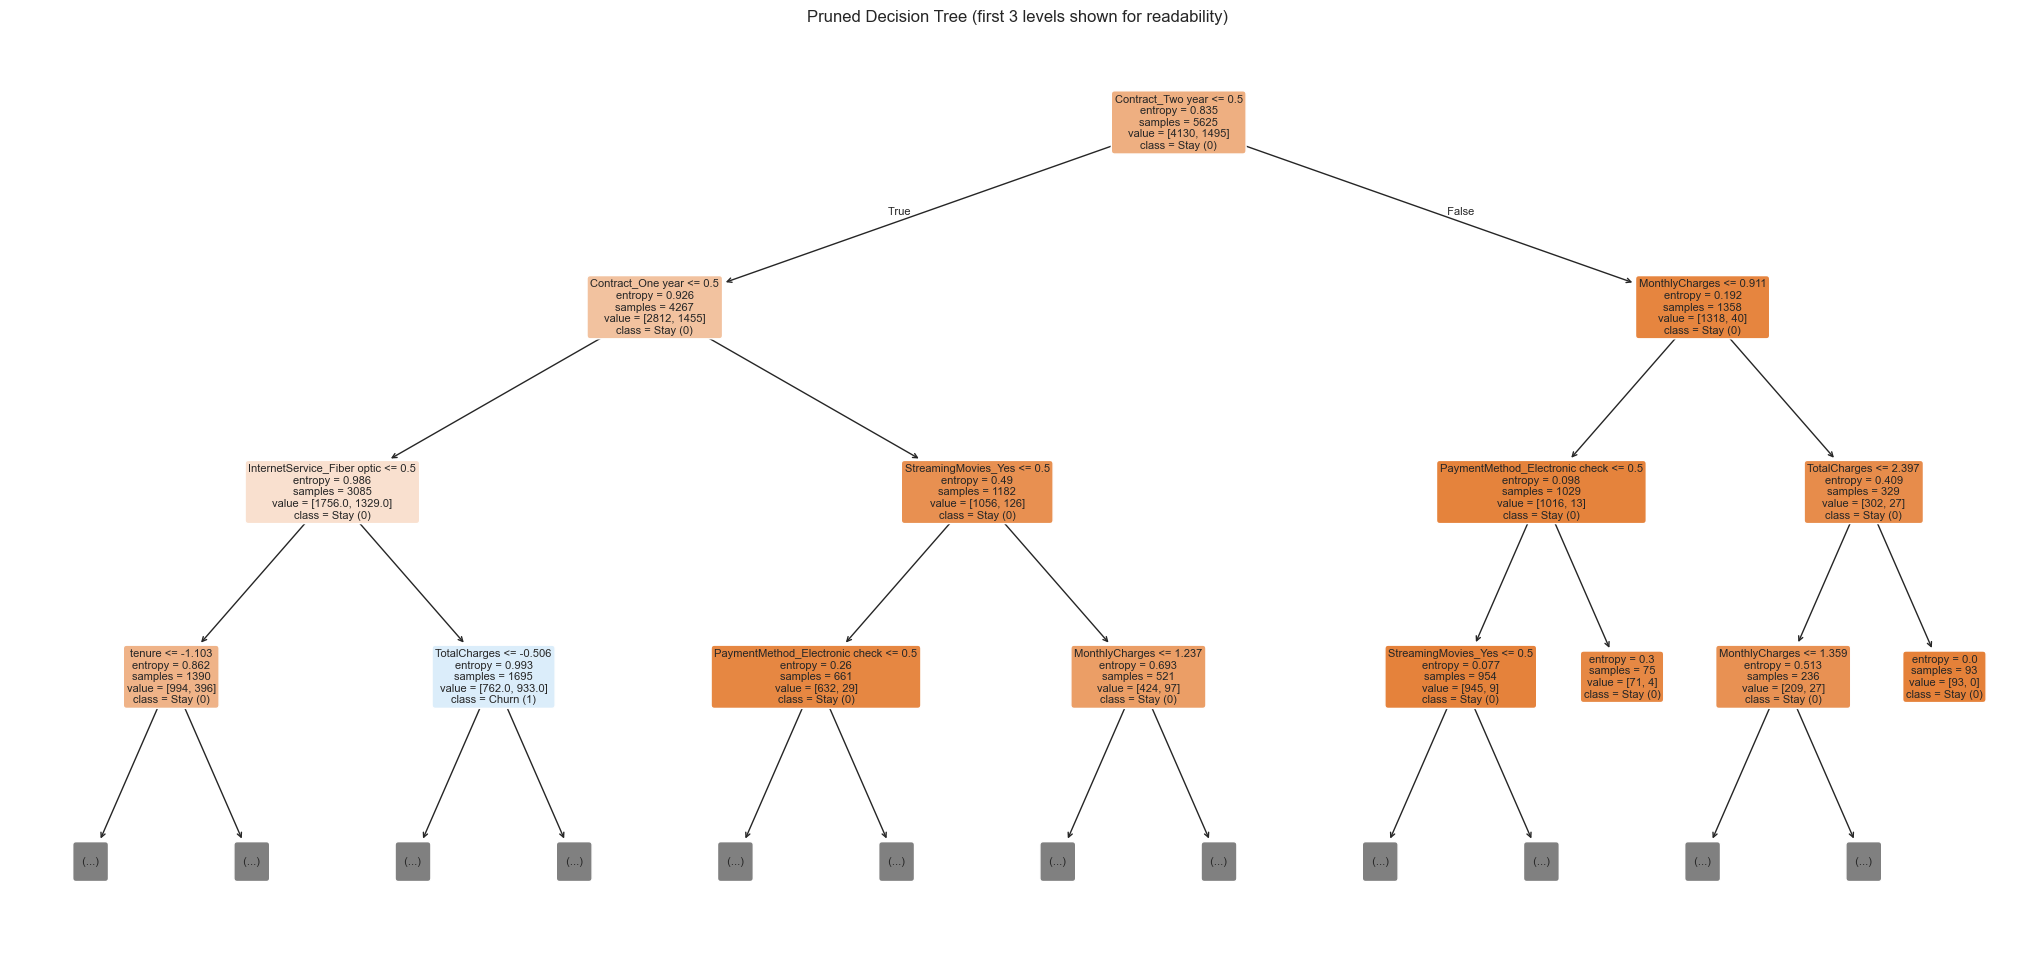

In [23]:
plt.figure(figsize=(26, 12))
plot_tree(dt_pruned,
          feature_names=X_train_scaled.columns,
          class_names=["Stay (0)", "Churn (1)"],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title("Pruned Decision Tree (first 3 levels shown for readability)")
plt.show()

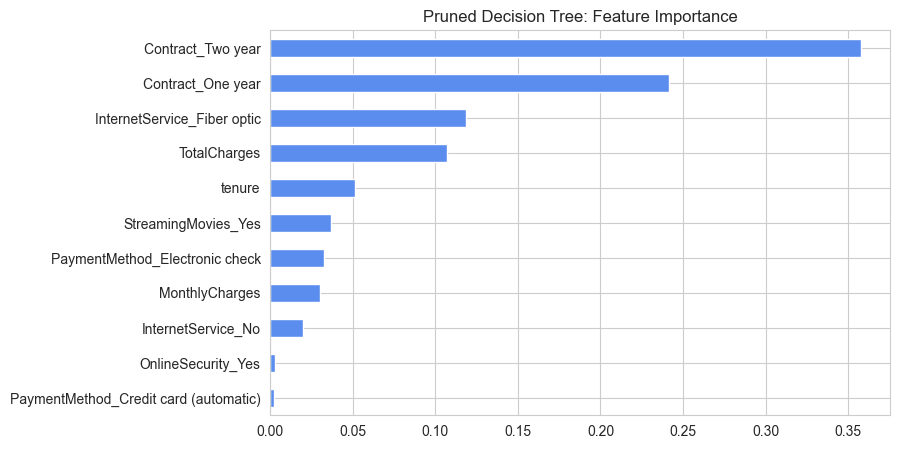

In [24]:
# The most important features according to the pruned tree
imp = pd.Series(dt_pruned.feature_importances_, index=X_train_scaled.columns)
imp = imp[imp > 0].sort_values()
plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="#5B8DEF")
plt.title("Pruned Decision Tree: Feature Importance")
plt.show()

**Interpreting the tree:** each box asks a yes/no question about one feature (e.g. "Is the contract month-to-month?"). Following the branches down to a leaf gives the predicted class. Box colors show the majority class (darker = more confident), and `samples` / `value` show how many customers reached that box. The features used near the top (check the feature-importance chart above, typically contract type, tenure and internet service) are the strongest drivers of churn, which agrees with what we saw in the Logistic Regression coefficients.

# Part 4: Ensemble Learning (Bagging and Boosting)
Ensembles combine many trees to get better, more stable predictions than a single tree.

### 4.1 Bagging: Random Forest (100 trees)
Each tree is trained on a random sample of the data, and the final answer is a **vote** across all trees.

In [25]:
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train_scaled, y_train)

print("Random Forest training accuracy:", round(rf.score(X_train_scaled, y_train), 4))
print("Random Forest testing accuracy :", round(rf.score(X_test_scaled, y_test), 4))

Random Forest training accuracy: 0.9988
Random Forest testing accuracy : 0.7882


### 4.2 Boosting: XGBoost (evaluation metric = log loss)
Trees are built **one after another**, and each new tree tries to correct the mistakes of the previous ones.

In [26]:
xgb = XGBClassifier(n_estimators=100, eval_metric="logloss", random_state=RANDOM_STATE)
xgb.fit(X_train_scaled, y_train)

print("XGBoost training accuracy:", round(xgb.score(X_train_scaled, y_train), 4))
print("XGBoost testing accuracy :", round(xgb.score(X_test_scaled, y_test), 4))

XGBoost training accuracy: 0.9365
XGBoost testing accuracy : 0.7711


# Part 5: Model Evaluation and Comparison
### 5.1 Predictions on the test set for all four models

In [27]:
models = {
    "Logistic Regression": log_reg,
    "Pruned Decision Tree": dt_pruned,
    "Random Forest": rf,
    "XGBoost": xgb,
}

predictions = {}   # class predictions (0/1)
probabilities = {} # probability of churn (needed for ROC)

for name, model in models.items():
    predictions[name] = model.predict(X_test_scaled)
    probabilities[name] = model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated for:", list(models.keys()))

Predictions generated for: ['Logistic Regression', 'Pruned Decision Tree', 'Random Forest', 'XGBoost']


### 5.2 Comparison table (Accuracy, Precision, Recall, F1-Score)
- **Accuracy:** share of all predictions that are correct
- **Precision:** of customers predicted to churn, how many really churned
- **Recall:** of customers who really churned, how many we caught (most important here)
- **F1-Score:** balance between Precision and Recall

In [28]:
rows = []
for name in models:
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions[name]),
        "Precision": precision_score(y_test, predictions[name]),
        "Recall": recall_score(y_test, predictions[name]),
        "F1-Score": f1_score(y_test, predictions[name]),
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4).style.highlight_max(axis=0, color="lightgreen"))

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.804500,0.650500,0.572200,0.608800
Pruned Decision Tree,0.775400,0.598000,0.473300,0.528400
Random Forest,0.788200,0.623400,0.513400,0.563000
XGBoost,0.771100,0.576000,0.526700,0.550300


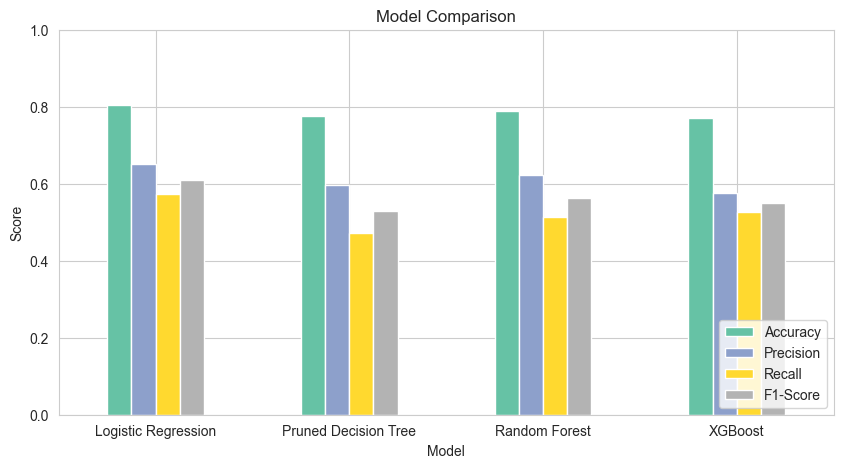

In [29]:
results.plot(kind="bar", figsize=(10, 5), colormap="Set2")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

### 5.3 Model with the highest Recall + Confusion Matrix
Failing to detect a churning customer (a *false negative*) is costly, so we pick the model with the highest **Recall**.

Model with the highest Recall: Logistic Regression  (Recall = 0.5722)


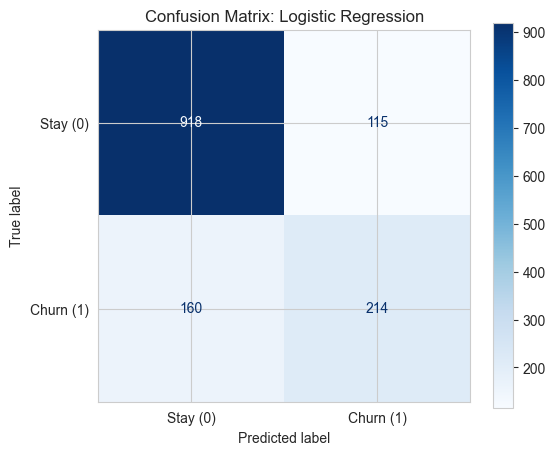

True Negatives (correctly predicted stay)   : 918
False Positives (false alarms)              : 115
False Negatives (missed churners, costly!)  : 160
True Positives (correctly caught churners)  : 214


In [30]:
best_recall_model = results["Recall"].idxmax()
print(f"Model with the highest Recall: {best_recall_model}  (Recall = {results.loc[best_recall_model, 'Recall']:.4f})")

cm = confusion_matrix(y_test, predictions[best_recall_model])
disp = ConfusionMatrixDisplay(cm, display_labels=["Stay (0)", "Churn (1)"])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title(f"Confusion Matrix: {best_recall_model}")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (correctly predicted stay)   : {tn}")
print(f"False Positives (false alarms)              : {fp}")
print(f"False Negatives (missed churners, costly!)  : {fn}")
print(f"True Positives (correctly caught churners)  : {tp}")

### 5.4 ROC curves and AUC for all four models

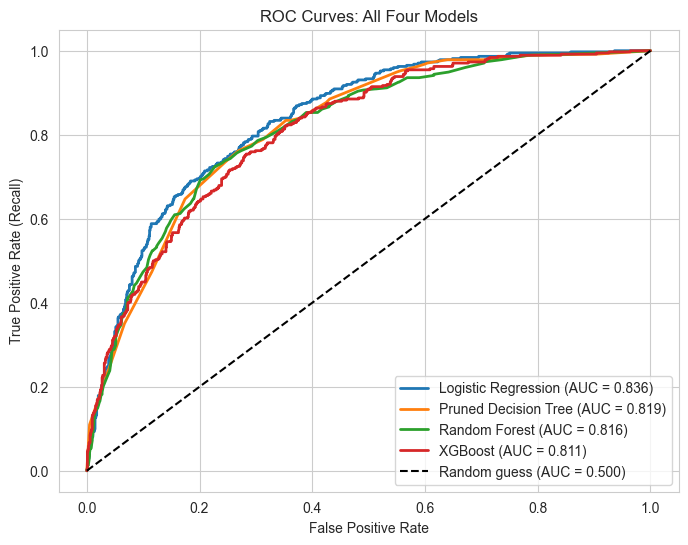

,AUC
Logistic Regression,0.8361
Pruned Decision Tree,0.8192
Random Forest,0.8156
XGBoost,0.8114


In [31]:
plt.figure(figsize=(8, 6))
auc_scores = {}
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_scores[name] = roc_auc_score(y_test, probabilities[name])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc_scores[name]:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves: All Four Models")
plt.legend(loc="lower right")
plt.show()

auc_df = pd.Series(auc_scores, name="AUC").sort_values(ascending=False).round(4)
display(auc_df.to_frame())

### 5.5 Final summary

In [32]:
best_auc_model = max(auc_scores, key=auc_scores.get)
best_f1_model = results["F1-Score"].idxmax()
best_acc_model = results["Accuracy"].idxmax()

summary = results.copy()
summary["AUC"] = pd.Series(auc_scores)
display(summary.round(4))

print(f"Best Accuracy : {best_acc_model}")
print(f"Best F1-Score : {best_f1_model}")
print(f"Best Recall   : {best_recall_model}")
print(f"Best AUC      : {best_auc_model} ({auc_scores[best_auc_model]:.4f})")

,Accuracy,Precision,Recall,F1-Score,AUC
Model,,,,,
Logistic Regression,0.8045,0.6505,0.5722,0.6088,0.8361
Pruned Decision Tree,0.7754,0.5980,0.4733,0.5284,0.8192
Random Forest,0.7882,0.6234,0.5134,0.5630,0.8156
XGBoost,0.7711,0.5760,0.5267,0.5503,0.8114


Best Accuracy : Logistic Regression
Best F1-Score : Logistic Regression
Best Recall   : Logistic Regression
Best AUC      : Logistic Regression (0.8361)


## Conclusions
1. **Data:** after dropping 11 rows with blank `TotalCharges` (customers with tenure 0), 7,032 customers remained. About 26.6% churned, so the classes are imbalanced.
2. **Churn drivers (Logistic Regression):** fiber optic internet, electronic-check payment and streaming add-ons increase churn risk, while long tenure and one/two-year contracts, online security and tech support reduce it.
3. **Overfitting:** the unconstrained tree reached ~99.9% training accuracy but only ~72.8% on test data. The pruned tree (~79.3% train, ~77.5% test) generalizes much better.
4. **Ensembles:** Random Forest (test accuracy ~78.8%) and XGBoost (~77.1%) improved on or matched the pruned tree in accuracy, but both fit the training data very closely (~99.9% and ~93.7%), so they overfit somewhat with default settings. Tuning (e.g. limiting depth) would likely help.
5. **Best model on this data:** **Logistic Regression** had the best Accuracy (0.8045), Precision (0.6505), Recall (0.5722), F1 (0.6088) and AUC (0.8361). On a dataset with mostly linear patterns and a modest number of features, a simple model can beat more complex ones with default settings.
6. **Recall:** even the best model catches only about 57% of churners at the default 0.5 threshold because the data is imbalanced. In practice one could lower the decision threshold or use class weights to boost Recall (at the cost of more false alarms).